## LQD: iShares Investment-Grade Corporate Bond
### Strategy 1: Moving Average Trend Strategy (v2: grid search + out-of-sample test)

Builds on the original `strategy_moving_average.ipynb`. What changed:

1. **Look-ahead bias fixed.** The signal is computed from day *t*'s close, so the position is only held from day *t+1* (`signal.shift(1)`). The original applied day *t*'s signal to day *t*'s return.
2. **Train / test split.** Moving-average windows are chosen on **2004-2017 only** (in-sample). The chosen settings are then evaluated on **2018-today** (out-of-sample), a period never used to pick them.
3. **Wider grid.** Fast and slow windows, **SMA vs EMA**, and **long/short vs long/flat** (hold cash instead of shorting).
4. **Robust selection.** Instead of the single best cell (often a lucky spike), we pick the cell whose *neighbourhood* of nearby settings has the best average Sharpe.
5. **Heatmaps** of in-sample Sharpe across the grid, plus a check of whether in-sample ranks carry over out-of-sample.
6. **Full metrics required by the brief**: daily and annualised mean return and standard deviation, CAGR, cumulative return, max drawdown, Sharpe, time in market, trades per year, all against buy-and-hold.
7. **Transaction costs** (default 1 bp per 100% of capital traded) and **saved data** (`LQD_daily.csv`) so results are reproducible.

In [ ]:
import os
from datetime import date

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

### Settings

In [ ]:
TICKER = 'LQD'
START_DATE = date(2002, 12, 31)
END_DATE = date.today()

DATA_FILE = 'LQD_daily.csv'   # saved copy of the data, so everyone gets the same numbers
REFRESH_DATA = False          # True = re-download from Yahoo Finance and overwrite DATA_FILE

# 2003 is only used to warm up the long moving averages (up to 250 days)
TRAIN_START = '2004-01-01'
TRAIN_END   = '2017-12-31'
TEST_START  = '2018-01-01'

TRADING_DAYS = 252
COST_BPS = 1.0   # cost in basis points per 100% of capital traded (a long -> short flip trades 200%)

# Grid
FAST_WINDOWS = list(range(5, 55, 5))      # 5, 10, ..., 50
SLOW_WINDOWS = list(range(20, 260, 10))   # 20, 30, ..., 250
MA_TYPES = ['sma', 'ema']
MODES = ['long_short', 'long_flat']

# Original notebook's best pair, kept for comparison
ORIGINAL_FAST, ORIGINAL_SLOW = 10, 100

### Data
Adjusted close (`auto_adjust=True`) so the monthly coupon distributions are included, i.e. returns are **total returns**.

In [ ]:
def load_prices() -> pd.Series:
    '''Load LQD adjusted close from DATA_FILE, or download it with yfinance and save it.'''
    if not REFRESH_DATA and os.path.exists(DATA_FILE):
        prices = pd.read_csv(DATA_FILE, index_col=0, parse_dates=True)[TICKER]
        print(f'Loaded {len(prices):,} rows from {DATA_FILE}')
        return prices

    import yfinance as yf
    raw = yf.download(
        TICKER,
        start=START_DATE.strftime('%Y-%m-%d'),
        end=END_DATE.strftime('%Y-%m-%d'),
        auto_adjust=True,
        progress=False,
    )['Close']
    prices = raw[TICKER] if isinstance(raw, pd.DataFrame) else raw
    prices = prices.dropna().rename(TICKER)
    prices.index.name = 'Date'
    prices.to_frame().to_csv(DATA_FILE)
    print(f'Downloaded {len(prices):,} rows and saved to {DATA_FILE}')
    return prices


prices = load_prices()
print(f'{prices.index[0].date()} to {prices.index[-1].date()}')
prices.tail()

Downloaded 6,012 rows and saved to LQD_daily.csv
2002-12-31 to 2026-11-20


,LQD
Date,
2026-11-16,102.800003
2026-11-17,102.739998
2026-11-18,103.150002
2026-11-19,103.080002
2026-11-20,103.690002


### Signal, back-test and statistics

In [ ]:
def moving_avg_signal(prices: pd.Series, fast_window: int, slow_window: int,
                      mode: str = 'long_short', ma_type: str = 'sma') -> pd.Series:
    '''
    Target position decided at the CLOSE of each day.

    +1 when the fast MA is above the slow MA.
    When it is below: -1 if mode == 'long_short', 0 (cash) if mode == 'long_flat'.
    0 while the slow MA is still warming up.
    '''
    if ma_type == 'sma':
        fast = prices.rolling(fast_window).mean()
        slow = prices.rolling(slow_window).mean()
    elif ma_type == 'ema':
        fast = prices.ewm(span=fast_window, adjust=False, min_periods=fast_window).mean()
        slow = prices.ewm(span=slow_window, adjust=False, min_periods=slow_window).mean()
    else:
        raise ValueError(f'unknown ma_type: {ma_type}')

    gap = fast - slow
    below = -1 if mode == 'long_short' else 0
    signal = np.where(gap > 0, 1, np.where(gap < 0, below, 0))   # NaN gap -> 0
    return pd.Series(signal, index=prices.index, name='signal')


def backtest(prices: pd.Series, signal: pd.Series, cost_bps: float = COST_BPS,
             lag: int = 1) -> pd.DataFrame:
    '''
    Daily back-test.

    lag=1 (default): a signal formed at day t's close is held over day t+1 -> no look-ahead.
    lag=0 reproduces the original notebook's look-ahead bias (for comparison only).
    '''
    asset_ret = prices.pct_change().fillna(0.0)
    position = signal.shift(lag).fillna(0.0)
    turnover = position.diff().abs().fillna(position.abs())
    strategy_ret = position * asset_ret - turnover * cost_bps / 10_000
    return pd.DataFrame({
        'price': prices,
        'signal': signal,
        'position': position,
        'asset_ret': asset_ret,
        'strategy_ret': strategy_ret,
    })


def max_drawdown(daily_ret: pd.Series) -> float:
    equity = (1 + daily_ret).cumprod()
    peak = equity.cummax().clip(lower=1.0)   # starting capital counts as the first peak
    return (equity / peak - 1).min()


def performance_stats(daily_ret: pd.Series, position: pd.Series | None = None) -> dict:
    '''All statistics required by the project brief, from a series of daily returns.'''
    r = daily_ret.dropna()
    n_years = len(r) / TRADING_DAYS
    growth = (1 + r).prod()
    daily_mean, daily_std = r.mean(), r.std()
    ann_mean, ann_vol = daily_mean * TRADING_DAYS, daily_std * np.sqrt(TRADING_DAYS)

    stats = {
        'daily_mean': daily_mean,
        'daily_std': daily_std,
        'ann_mean': ann_mean,                 # arithmetic: daily mean x 252
        'ann_vol': ann_vol,                   # daily std x sqrt(252)
        'cagr': growth ** (1 / n_years) - 1,  # geometric (compound) annual return
        'cum_return': growth - 1,
        'max_drawdown': max_drawdown(r),
        'sharpe': ann_mean / ann_vol if ann_vol > 0 else np.nan,   # risk-free rate taken as 0
    }
    if position is not None:
        p = position.loc[r.index]
        stats['time_in_market'] = (p != 0).mean()
        stats['trades_per_year'] = (p.diff().fillna(0) != 0).sum() / n_years
    return stats


def period(df, start=None, end=None):
    return df.loc[start:end]

### Why the one-day lag matters

Same 10/100 SMA long/short strategy as the original notebook, with and without the lag. Any gap between the two rows is return the original version could not really have earned.

In [ ]:
orig_signal = moving_avg_signal(prices, ORIGINAL_FAST, ORIGINAL_SLOW, 'long_short', 'sma')
lookahead_check = pd.DataFrame({
    'No lag (original, look-ahead)': performance_stats(
        period(backtest(prices, orig_signal, cost_bps=0, lag=0), TRAIN_START)['strategy_ret']),
    'One-day lag (correct)': performance_stats(
        period(backtest(prices, orig_signal, cost_bps=0, lag=1), TRAIN_START)['strategy_ret']),
}).T[['ann_mean', 'ann_vol', 'cagr', 'max_drawdown', 'sharpe']]

lookahead_check.style.format('{:.2%}', subset=['ann_mean', 'ann_vol', 'cagr', 'max_drawdown']) \
                     .format('{:.2f}', subset=['sharpe'])

,ann_mean,ann_vol,cagr,max_drawdown,sharpe
"No lag (original, look-ahead)",3.90%,8.37%,3.61%,-23.81%,0.47
One-day lag (correct),1.86%,8.37%,1.52%,-26.53%,0.22


### Grid search (in-sample only: 2004-2017)

Every combination of fast window, slow window (fast < slow), MA type and long/short vs long/flat is back-tested on the full history (so the averages are warmed up), but **scored only on the training period**. Nothing from 2018 onward is used to choose settings.

In [ ]:
def run_grid(prices: pd.Series, start: str, end: str | None) -> pd.DataFrame:
    rows = []
    for ma_type in MA_TYPES:
        for mode in MODES:
            for fast in FAST_WINDOWS:
                for slow in SLOW_WINDOWS:
                    if fast >= slow:
                        continue
                    bt = period(backtest(prices, moving_avg_signal(prices, fast, slow, mode, ma_type)), start, end)
                    rows.append({'ma_type': ma_type, 'mode': mode, 'fast': fast, 'slow': slow,
                                 **performance_stats(bt['strategy_ret'], bt['position'])})
    return pd.DataFrame(rows)


train_grid = run_grid(prices, TRAIN_START, TRAIN_END)
print(f'{len(train_grid)} combinations tested')

(train_grid.sort_values('sharpe', ascending=False)
           .head(10)[['ma_type', 'mode', 'fast', 'slow', 'cagr', 'ann_vol', 'max_drawdown', 'sharpe', 'trades_per_year']]
           .style.format('{:.2%}', subset=['cagr', 'ann_vol', 'max_drawdown'])
                 .format('{:.2f}', subset=['sharpe', 'trades_per_year']))

896 combinations tested


,ma_type,mode,fast,slow,cagr,ann_vol,max_drawdown,sharpe,trades_per_year
679,ema,long_flat,5,90,5.15%,4.98%,-7.14%,1.03,4.00
680,ema,long_flat,5,100,5.01%,5.01%,-7.78%,1.00,3.86
702,ema,long_flat,10,80,4.87%,5.00%,-8.24%,0.98,3.00
678,ema,long_flat,5,80,4.81%,4.98%,-9.48%,0.97,5.01
701,ema,long_flat,10,70,4.74%,4.98%,-8.25%,0.96,3.86
682,ema,long_flat,5,120,4.78%,5.06%,-7.78%,0.95,3.15
681,ema,long_flat,5,110,4.75%,5.03%,-7.78%,0.95,3.43
703,ema,long_flat,10,90,4.66%,5.01%,-8.24%,0.93,3.00
748,ema,long_flat,20,70,4.65%,5.02%,-9.29%,0.93,2.57
685,ema,long_flat,5,150,4.70%,5.12%,-7.78%,0.92,2.86


### Robust selection

The single highest-Sharpe cell is often an isolated spike that won't repeat. For each MA type / mode we average each cell's Sharpe with its immediate neighbours (3x3 block on the heatmap) and choose the cell with the best **neighbourhood** Sharpe. Then, for each mode, we keep whichever MA type (SMA or EMA) scored higher.

In [ ]:
def sharpe_surface(grid: pd.DataFrame, ma_type: str, mode: str) -> pd.DataFrame:
    sub = grid[(grid['ma_type'] == ma_type) & (grid['mode'] == mode)]
    return sub.pivot(index='fast', columns='slow', values='sharpe')


def smooth(surface: pd.DataFrame) -> pd.DataFrame:
    '''Mean of each cell and its neighbours (ignores the empty fast >= slow cells).'''
    s = surface.rolling(3, center=True, min_periods=1).mean()
    s = s.T.rolling(3, center=True, min_periods=1).mean().T
    return s.where(surface.notna())


selected = {}
for mode in MODES:
    best = None
    for ma_type in MA_TYPES:
        sm = smooth(sharpe_surface(train_grid, ma_type, mode))
        r, c = np.unravel_index(np.nanargmax(sm.values), sm.shape)
        fast, slow = sm.index[r], sm.columns[c]
        score = sm.loc[fast, slow]
        if best is None or score > best['smoothed_sharpe']:
            raw = sharpe_surface(train_grid, ma_type, mode).loc[fast, slow]
            best = {'ma_type': ma_type, 'fast': int(fast), 'slow': int(slow),
                    'smoothed_sharpe': score, 'cell_sharpe': raw}
    selected[mode] = best

pd.DataFrame(selected).T

,ma_type,fast,slow,smoothed_sharpe,cell_sharpe
long_short,ema,5,90,0.547495,0.629078
long_flat,ema,5,90,0.964832,1.03358


### Heatmaps: in-sample Sharpe across the grid

Rows = fast window, columns = slow window. A broad warm region means the strategy works across many settings (robust); a single bright cell surrounded by cold ones means the "best" result is probably luck. Black box = selected setting.

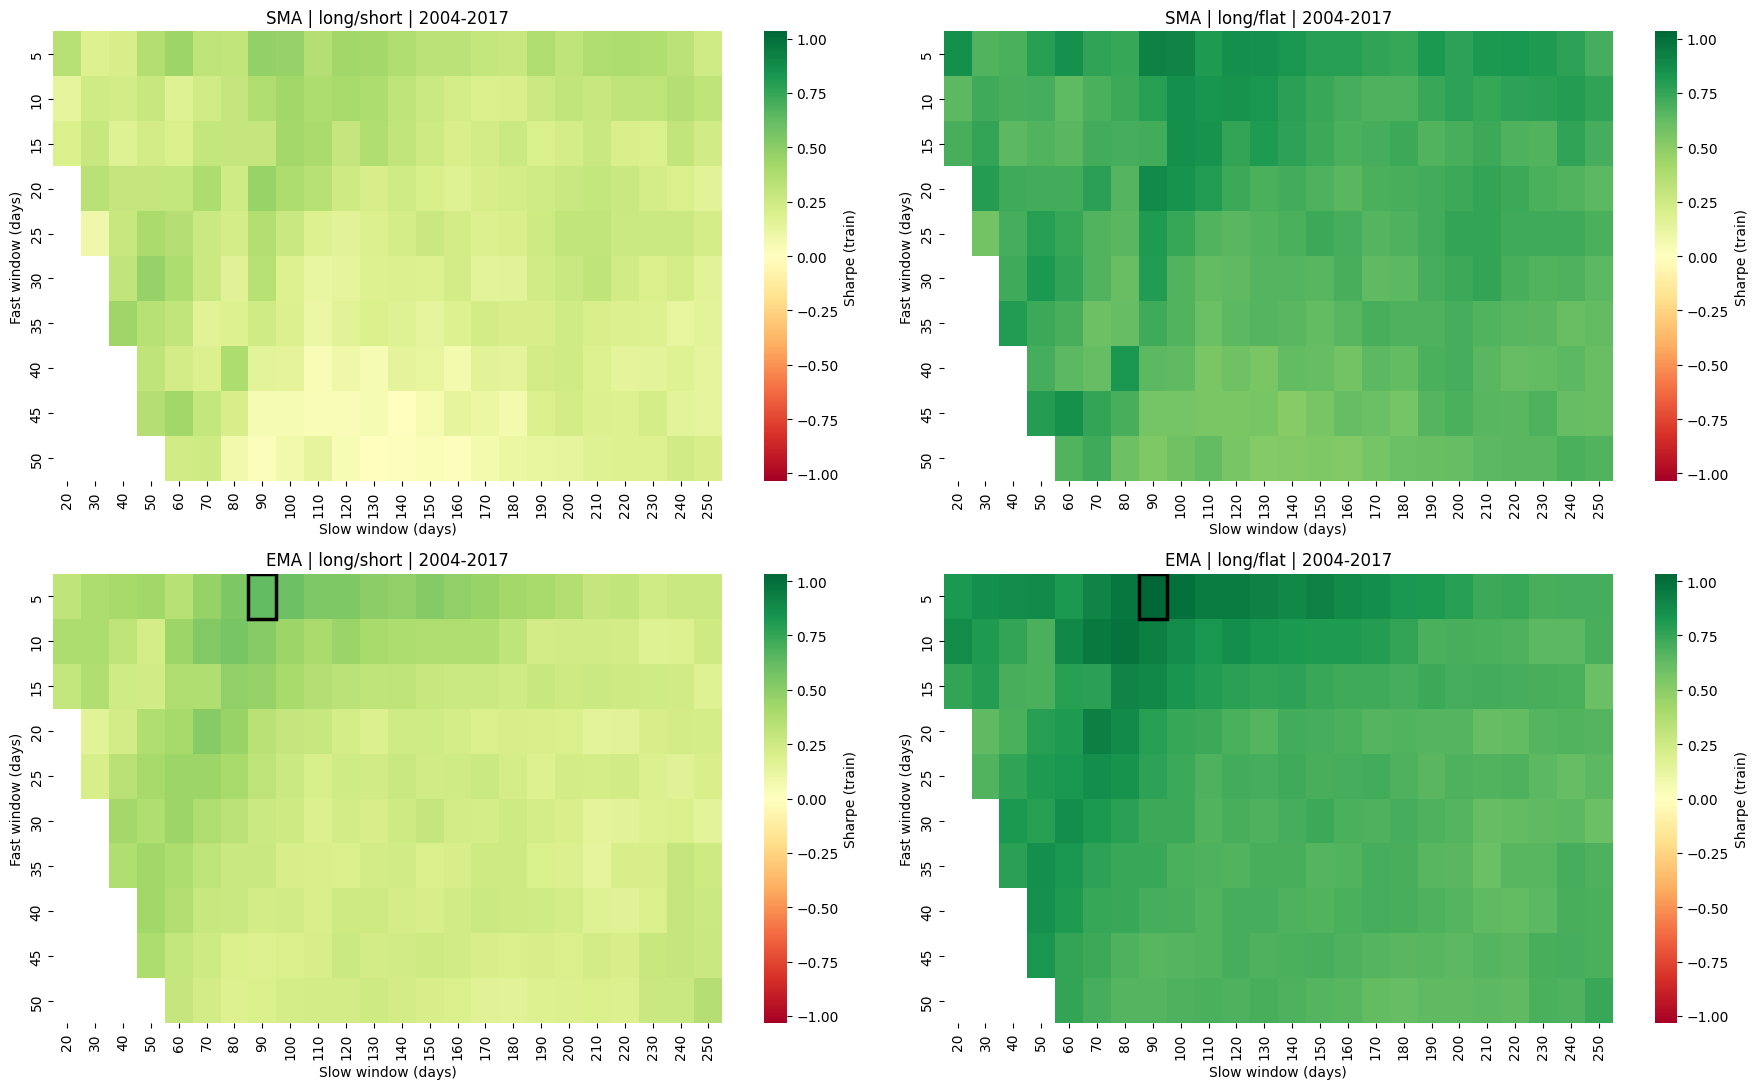

In [ ]:
vals = train_grid['sharpe']
vmax = np.nanmax(np.abs(vals))

fig, axes = plt.subplots(len(MA_TYPES), len(MODES), figsize=(18, 5.5 * len(MA_TYPES)), squeeze=False)
for i, ma_type in enumerate(MA_TYPES):
    for j, mode in enumerate(MODES):
        ax = axes[i, j]
        surf = sharpe_surface(train_grid, ma_type, mode)
        sns.heatmap(surf, ax=ax, cmap='RdYlGn', center=0, vmin=-vmax, vmax=vmax,
                    cbar_kws={'label': 'Sharpe (train)'})
        sel = selected[mode]
        if sel['ma_type'] == ma_type:
            r, c = surf.index.get_loc(sel['fast']), surf.columns.get_loc(sel['slow'])
            ax.add_patch(plt.Rectangle((c, r), 1, 1, fill=False, edgecolor='black', lw=2.5))
        ax.set_title(f'{ma_type.upper()} | {mode.replace("_", "/")} | {TRAIN_START[:4]}-{TRAIN_END[:4]}')
        ax.set_xlabel('Slow window (days)')
        ax.set_ylabel('Fast window (days)')
plt.tight_layout()
plt.show()

### Does in-sample ranking carry over out-of-sample? (diagnostic only)

This scores the **same grid** on 2018-today. It is **not used for selection**; it only shows whether combinations that looked good in training also did well afterwards. Points scattered with no upward slope mean the grid search is mostly fitting noise.

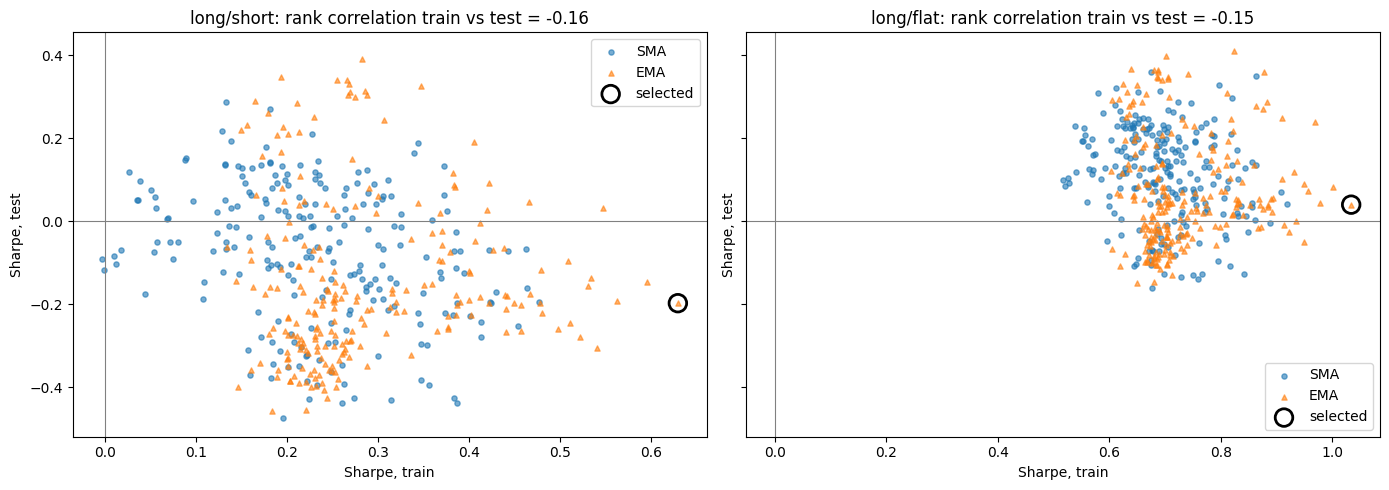

In [ ]:
test_grid = run_grid(prices, TEST_START, None)
both = train_grid.merge(test_grid, on=['ma_type', 'mode', 'fast', 'slow'], suffixes=('_train', '_test'))

fig, axes = plt.subplots(1, len(MODES), figsize=(14, 5), sharey=True)
for ax, mode in zip(axes, MODES):
    for ma_type, marker in zip(MA_TYPES, ['o', '^']):
        sub = both[(both['mode'] == mode) & (both['ma_type'] == ma_type)]
        ax.scatter(sub['sharpe_train'], sub['sharpe_test'], s=14, alpha=0.6, marker=marker, label=ma_type.upper())
    sel = selected[mode]
    pt = both[(both['mode'] == mode) & (both['ma_type'] == sel['ma_type'])
              & (both['fast'] == sel['fast']) & (both['slow'] == sel['slow'])]
    ax.scatter(pt['sharpe_train'], pt['sharpe_test'], s=160, facecolors='none', edgecolors='black', lw=2, label='selected')
    ax.axhline(0, color='grey', lw=0.8); ax.axvline(0, color='grey', lw=0.8)
    rank_corr = both.loc[both['mode'] == mode, ['sharpe_train', 'sharpe_test']].corr(method='spearman').iloc[0, 1]
    ax.set_title(f'{mode.replace("_", "/")}: rank correlation train vs test = {rank_corr:.2f}')
    ax.set_xlabel('Sharpe, train'); ax.set_ylabel('Sharpe, test')
    ax.legend()
plt.tight_layout()
plt.show()

### Results: selected strategies vs buy-and-hold

Statistics for the training period (in-sample), the test period (out-of-sample, the numbers that matter) and the full period.

In [ ]:
strategies = {
    'Buy & hold': pd.Series(1, index=prices.index),
    f'Original {ORIGINAL_FAST}/{ORIGINAL_SLOW} SMA L/S (lag fixed)':
        moving_avg_signal(prices, ORIGINAL_FAST, ORIGINAL_SLOW, 'long_short', 'sma'),
}
for mode, sel in selected.items():
    label = f"Optimised {sel['fast']}/{sel['slow']} {sel['ma_type'].upper()} {'L/S' if mode == 'long_short' else 'L/F'}"
    strategies[label] = moving_avg_signal(prices, sel['fast'], sel['slow'], mode, sel['ma_type'])

backtests = {name: backtest(prices, sig) for name, sig in strategies.items()}
# Buy & hold pays the cost once on day 1 only; set it to zero cost so it is a clean benchmark
backtests['Buy & hold'] = backtest(prices, strategies['Buy & hold'], cost_bps=0)

periods = {
    f'Train {TRAIN_START[:4]}-{TRAIN_END[:4]}': (TRAIN_START, TRAIN_END),
    f'Test {TEST_START[:4]}-{prices.index[-1].year}': (TEST_START, None),
    f'Full {TRAIN_START[:4]}-{prices.index[-1].year}': (TRAIN_START, None),
}

results = pd.concat({
    pname: pd.DataFrame({name: performance_stats(period(bt, s, e)['strategy_ret'], period(bt, s, e)['position'])
                         for name, bt in backtests.items()}).T
    for pname, (s, e) in periods.items()
})
results.index.names = ['period', 'strategy']

pct_cols = ['daily_mean', 'daily_std', 'ann_mean', 'ann_vol', 'cagr', 'cum_return', 'max_drawdown', 'time_in_market']
results.style.format('{:.2%}', subset=pct_cols).format('{:.3%}', subset=['daily_mean', 'daily_std']) \
             .format('{:.2f}', subset=['sharpe', 'trades_per_year'])

In [ ]:
# Save the results table for the report
results.to_csv('ma_strategy_results.csv')
train_grid.to_csv('ma_grid_train.csv', index=False)

### Equity curves and drawdowns

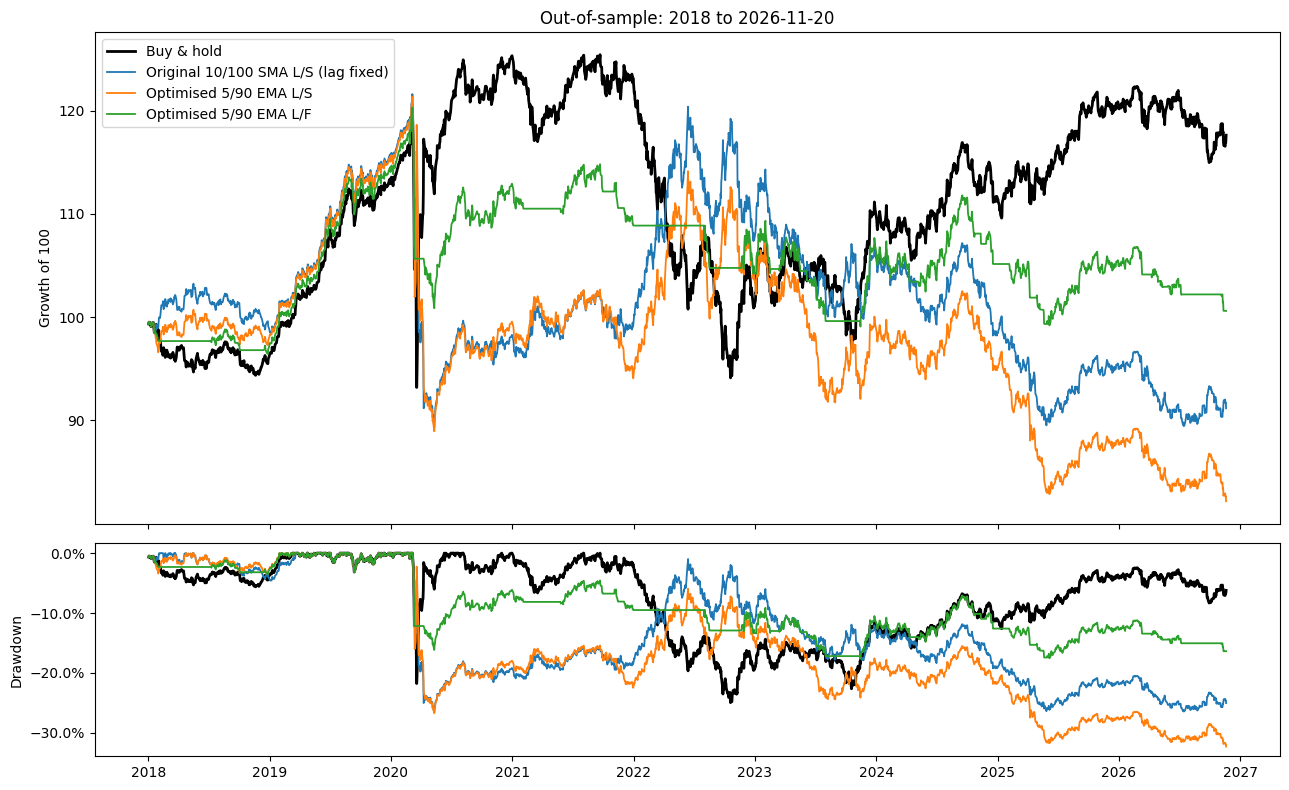

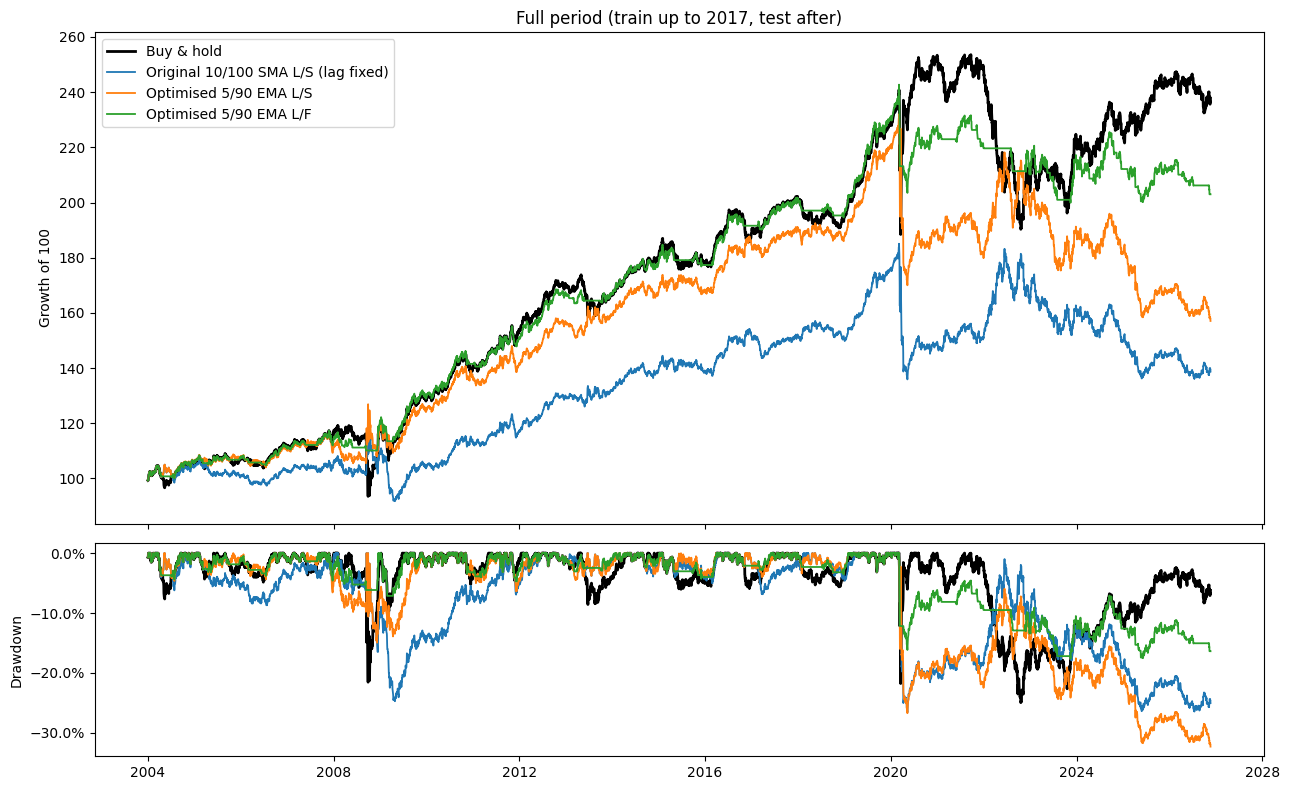

In [ ]:
def plot_equity(backtests: dict, start, end=None, title=''):
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(13, 8), sharex=True,
                                   gridspec_kw={'height_ratios': [3, 1.3]})
    for name, bt in backtests.items():
        r = period(bt, start, end)['strategy_ret']
        equity = 100 * (1 + r).cumprod()
        dd = equity / equity.cummax().clip(lower=100) - 1
        style = dict(color='black', lw=2) if name == 'Buy & hold' else dict(lw=1.3)
        ax1.plot(equity, label=name, **style)
        ax2.plot(dd, **style)
    ax1.set_ylabel('Growth of 100'); ax1.set_title(title); ax1.legend(loc='upper left')
    ax2.set_ylabel('Drawdown'); ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
    plt.tight_layout()
    plt.show()


plot_equity(backtests, TEST_START, title=f'Out-of-sample: {TEST_START[:4]} to {prices.index[-1].date()}')
plot_equity(backtests, TRAIN_START, title=f'Full period (train up to {TRAIN_END[:4]}, test after)')